---
title: "Tidal forces and tides"
subtitle: ""
description: ""
author: "Basics"
date: "2026-11-22"
categories: [classical mechanics, tidal force, tides, fluid statics]
section: 1
---

This post follows a video by *"La Fisica che non ti aspetti"* about tides and tidal forces. Here we derive the tidal acceleration field from first principles using relative kinematics between the **Earth–Moon barycentric frame** and the **Earth-fixed rotating frame**, and then integrate the **hydrostatic equilibrium equations** for an idealized global ocean (the equilibrium tide model) both **analytically** and **numerically**.

A (tidal coefficient)                 = 0.5349 m
B (rotation coefficient)              = 10989.2 m
zeta0 analytic = -A/3 - 2B/3          = -7326.335 m
zeta0 numeric (theta1=  0.0 deg)       = -7326.335 m
zeta0 numeric (theta1= 37.0 deg)       = -7326.335 m
zeta0 numeric (theta1=123.0 deg)       = -7326.335 m
tidal peak-to-peak (equilibrium)      = 0.535 m
exact vs quadrupole potential, max |d zeta| = 0.57 cm (octupole ~ r0/R_EM = 1.7%)
a_E (CM to Earth centre) = 4668 km  (< r0 = 6371 km: the CM is inside the Earth)


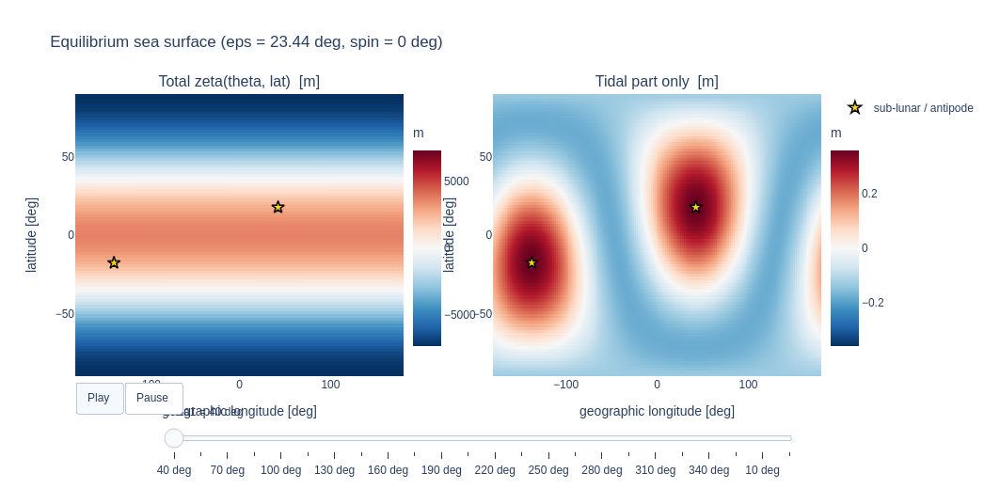

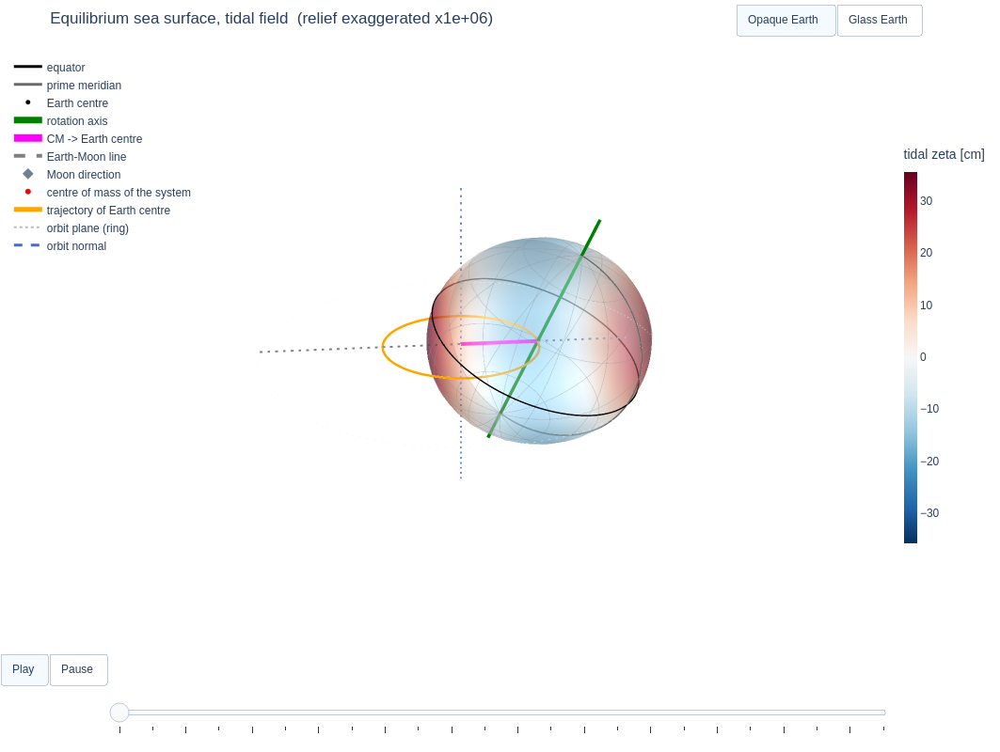

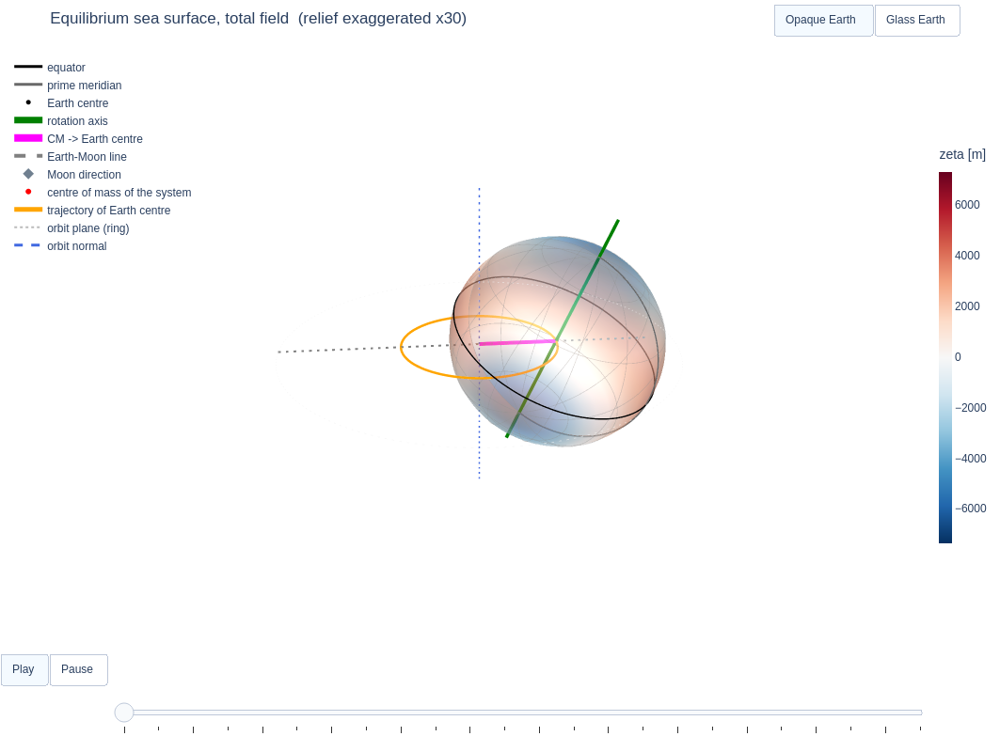

In [1]:
# -*- coding: utf-8 -*-
"""
Equilibrium tide + rotational flattening of the sea surface, Earth-Moon system
==============================================================================
Free surface (first order, point-mass gravity, aquaplanet):

    zeta(theta, lat) = zeta0
                     + (3/2) (M_m/M_E) (r0^4 / R_EM^3) * (x1 . R0)^2
                     + (1/2) (Omega^2 r0^4 / (G M_E))  * cos^2(lat)

    x1 . R0 = cos(theta1) [cos(eps) cos(lat) cos(theta) + sin(eps) sin(lat)]
            + sin(theta1)  cos(lat) sin(theta)

Conventions
  * orbit plane = (X, Y); Z = orbit normal
  * x1      = unit vector CM -> Earth centre = (cos th1, sin th1, 0)
              (parallel to the Earth-Moon line, so only (x1.R0)^2 matters)
  * spin axis = (sin eps, 0, cos eps); eps = angle between axis and orbit normal
  * theta   = inertial azimuth of a surface point  (= geographic longitude + spin)
  * lat     = latitude.  (Your colatitude phi:  sin(phi) = cos(lat), cos(phi) = sin(lat))
  * zeta0 fixed by volume conservation:  mean of zeta over the sphere = 0

Run in Google Colab as a single cell (plotly and numpy are preinstalled).
"""
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ───────────────────────── physical constants (SI) ─────────────────────────
G     = 6.67430e-11
M_E   = 5.9722e24          # Earth mass [kg]
M_m   = 7.342e22           # Moon mass  [kg]
r0    = 6.371e6            # mean Earth radius [m]
R_EM  = 3.844e8            # Earth-Moon distance [m]
Omega = 7.2921159e-5       # Earth spin rate [rad/s]

# ───────────────────────── user parameters ─────────────────────────
EPS_DEG       = 23.44      # obliquity: angle between spin axis and orbit normal
THETA1_DEG    = 40.0       # orbital phase of the Earth centre shown at start
SPIN_DEG      = 0.0        # Earth rotation phase (theta = longitude + spin)
N_FRAMES      = 24         # frames of the theta1 slider/animation
SHOW_3D       = ["tidal", "total"]   # 3D figures to draw: any of "tidal", "total", "rotation"
EXAG          = {"tidal": 1e6, "total": 30.0, "rotation": 30.0}   # radial relief exaggeration
EARTH_OPACITY = 0.45       # initial opacity (<1 shows the CM/orbit inside the Earth); buttons toggle it

eps  = np.radians(EPS_DEG)
spin = np.radians(SPIN_DEG)

# ───────────────────────── derived quantities ─────────────────────────
a_E = R_EM * M_m / (M_E + M_m)               # radius of the Earth-centre orbit around the CM
g0  = G * M_E / r0**2
A   = 1.5 * (M_m / M_E) * r0**4 / R_EM**3    # coefficient of (x1.R0)^2   [m]
B   = 0.5 * Omega**2 * r0**4 / (G * M_E)     # coefficient of cos^2(lat)  [m]

# ───────────────────────── geometry ─────────────────────────
EZ = np.array([np.sin(eps), 0.0,  np.cos(eps)])    # spin axis
EA = np.array([np.cos(eps), 0.0, -np.sin(eps)])    # body x (theta = 0 meridian)
EB = np.array([0.0, 1.0, 0.0])                     # body y


def R0_hat(theta, lat):
    """Unit vector (inertial frame) of the surface point (theta, lat)."""
    theta, lat = np.broadcast_arrays(theta, lat)
    return ((np.cos(lat) * np.cos(theta))[..., None] * EA
            + (np.cos(lat) * np.sin(theta))[..., None] * EB
            + np.sin(lat)[..., None] * EZ)


def x1_hat(theta1):
    return np.array([np.cos(theta1), np.sin(theta1), 0.0])


def cos_psi_vec(theta1, theta, lat):
    """x1 . R0 computed with explicit vectors (independent check)."""
    return R0_hat(theta, lat) @ x1_hat(theta1)


def cos_psi(theta1, theta, lat):
    """x1 . R0 in closed form (your formula, latitude version)."""
    return (np.cos(theta1) * (np.cos(eps) * np.cos(lat) * np.cos(theta)
                              + np.sin(eps) * np.sin(lat))
            + np.sin(theta1) * np.cos(lat) * np.sin(theta))


def cos_psi_paper(theta1, theta, phi):
    """Your formula with phi = COLATITUDE (cos(phi) cos(theta) -> sin(phi) cos(theta)).
    Sign of the sin(eps) term: + here; the '-' in your note corresponds to measuring
    theta from the opposite meridian (theta -> theta + pi), physically equivalent."""
    return (np.cos(eps) * np.cos(theta1) * np.sin(phi) * np.cos(theta)
            + np.sin(theta1) * np.sin(phi) * np.sin(theta)
            + np.sin(eps) * np.cos(theta1) * np.cos(phi))


# ───────────────────────── fields ─────────────────────────
def zeta_tidal(theta1, theta, lat):          # zero-mean tidal part
    return A * (cos_psi(theta1, theta, lat) ** 2 - 1.0 / 3.0)


def zeta_rot(lat):                           # zero-mean rotational flattening
    return B * (np.cos(lat) ** 2 - 2.0 / 3.0)


def zeta_full(theta1, theta, lat, zeta0):
    return zeta0 + A * cos_psi(theta1, theta, lat) ** 2 + B * np.cos(lat) ** 2


def sphere_mean(f, n=64, m=128):
    """Exact-for-polynomials average over the sphere (Gauss-Legendre in sin(lat))."""
    x, w = np.polynomial.legendre.leggauss(n)
    lat = np.arcsin(x)
    lon = np.linspace(0, 2 * np.pi, m, endpoint=False)
    LON, LAT = np.meshgrid(lon, lat)
    return np.sum(f(LON, LAT) * w[:, None]) / (w.sum() * m)


def find_zeta0(theta1):
    """Volume conservation: <zeta> = 0 over the sphere. <zeta> is linear in zeta0,
    so the root is exactly  zeta0 = -<zeta(zeta0 = 0)>."""
    return -sphere_mean(lambda th, la: zeta_full(theta1, th, la, 0.0))


zeta0_analytic = -A / 3.0 - 2.0 * B / 3.0

# ───────────────────────── self-checks ─────────────────────────
rng = np.random.default_rng(0)
th1, th, la = rng.uniform(0, 2 * np.pi, 3), rng.uniform(0, 2 * np.pi, 200), rng.uniform(-1.5, 1.5, 200)
for t1 in th1:
    assert np.allclose(cos_psi(t1, th, la), cos_psi_vec(t1, th, la)), "closed form != vector form"
    assert np.allclose(cos_psi(t1, th, la), cos_psi_paper(t1, th, np.pi / 2 - la)), "colatitude form mismatch"

# exact Moon potential (no multipole expansion) in the Earth-centred, non-rotating frame:
#   Phi = -G M_m/|d - r| + (G M_m/R^2) d.r      (second term: inertial force from the Earth's acceleration)
t1 = np.radians(THETA1_DEG)
d_hat = -x1_hat(t1)
R_pts = r0 * R0_hat(th, la)
Phi_exact = (-G * M_m / np.linalg.norm(R_EM * d_hat - R_pts, axis=-1)
             + G * M_m / R_EM**2 * (R_pts @ d_hat))
Phi_quad = -G * M_m * r0**2 / R_EM**3 * (1.5 * cos_psi(t1, th, la) ** 2 - 0.5)
dz_exact = -(Phi_exact + G * M_m / R_EM) / g0          # remove the constant -G M_m / R
dz_quad = -Phi_quad / g0
print("A (tidal coefficient)                 = %.4f m" % A)
print("B (rotation coefficient)              = %.1f m" % B)
print("zeta0 analytic = -A/3 - 2B/3          = %.3f m" % zeta0_analytic)
for t1_ in np.radians([0, 37, 123]):
    print("zeta0 numeric (theta1=%5.1f deg)       = %.3f m" % (np.degrees(t1_), find_zeta0(t1_)))
print("tidal peak-to-peak (equilibrium)      = %.3f m" % (A * (1 - 0.0)))   # cos^2 from 0 to 1
print("exact vs quadrupole potential, max |d zeta| = %.2f cm (octupole ~ r0/R_EM = %.1f%%)"
      % (100 * np.max(np.abs((dz_exact - dz_exact.mean()) - (dz_quad - dz_quad.mean()))),
         100 * r0 / R_EM))
print("a_E (CM to Earth centre) = %.0f km  (< r0 = %.0f km: the CM is inside the Earth)"
      % (a_E / 1e3, r0 / 1e3))

# ───────────────────────── helper: sub-lunar point ─────────────────────────
def wrap180(x):
    return (x + 180.0) % 360.0 - 180.0


def sublunar(theta1):
    m = -x1_hat(theta1)                                  # direction Earth -> Moon
    lat_s = np.degrees(np.arcsin(m @ EZ))
    L_s = wrap180(np.degrees(np.arctan2(m @ EB, m @ EA)) - SPIN_DEG)
    return [L_s, wrap180(L_s + 180.0)], [lat_s, -lat_s]  # sub-lunar and antipodal points


def add_controls(fig, names, labels, prefix="theta1 = "):
    anim = dict(frame=dict(duration=120, redraw=True), transition=dict(duration=0))
    fig.update_layout(
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.02, xanchor="left", yanchor="top",
                          buttons=[dict(label="Play", method="animate", args=[None, dict(anim, fromcurrent=True)]),
                                   dict(label="Pause", method="animate",
                                        args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False),
                                                           transition=dict(duration=0))])])],
        sliders=[dict(active=0, x=0.12, len=0.85, y=-0.02, yanchor="top",
                      currentvalue=dict(prefix=prefix),
                      steps=[dict(method="animate", label=lb,
                                  args=[[nm], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                   transition=dict(duration=0))])
                             for nm, lb in zip(names, labels)])])


theta1_list = np.radians(THETA1_DEG) + 2 * np.pi * np.arange(N_FRAMES) / N_FRAMES
names  = [str(k) for k in range(N_FRAMES)]
labels = ["%.0f deg" % (np.degrees(t) % 360) for t in theta1_list]

# ═════════════════════════ 2D maps ═════════════════════════
lon_d = np.linspace(-180, 180, 181)
lat_d = np.linspace(-90, 90, 91)
LON2, LAT2 = np.meshgrid(np.radians(lon_d), np.radians(lat_d))


def maps2d(theta1):
    th = LON2 + spin
    z0 = find_zeta0(theta1)
    return zeta_full(theta1, th, LAT2, z0), zeta_tidal(theta1, th, LAT2)


tot_all = [maps2d(t)[0] for t in theta1_list]
lim_tot = max(np.abs(z).max() for z in tot_all)
lim_tid = 2 * A / 3

fig2d = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                      subplot_titles=("Total zeta(theta, lat)  [m]", "Tidal part only  [m]"))


def frame2d(k):
    Zt, Zd = maps2d(theta1_list[k])
    Ls, Bs = sublunar(theta1_list[k])
    mk = dict(size=10, color="gold", line=dict(color="black", width=1.5), symbol="star")
    return [go.Heatmap(x=lon_d, y=lat_d, z=np.round(Zt, 4), zmin=-lim_tot, zmax=lim_tot, colorscale="RdBu_r",
                       colorbar=dict(title="m", x=0.44, len=0.85),
                       hovertemplate="lon %{x:.0f} lat %{y:.0f}<br>zeta = %{z:.3f} m<extra></extra>"),
            go.Heatmap(x=lon_d, y=lat_d, z=np.round(Zd, 4), zmin=-lim_tid, zmax=lim_tid, colorscale="RdBu_r",
                       colorbar=dict(title="m", x=1.0, len=0.85),
                       hovertemplate="lon %{x:.0f} lat %{y:.0f}<br>zeta_tide = %{z:.3f} m<extra></extra>"),
            go.Scatter(x=Ls, y=Bs, mode="markers", marker=mk, name="sub-lunar / antipode", showlegend=True),
            go.Scatter(x=Ls, y=Bs, mode="markers", marker=mk, showlegend=False)]


d0 = frame2d(0)
fig2d.add_trace(d0[0], row=1, col=1)
fig2d.add_trace(d0[1], row=1, col=2)
fig2d.add_trace(d0[2], row=1, col=1)
fig2d.add_trace(d0[3], row=1, col=2)
fig2d.frames = [go.Frame(name=names[k], data=frame2d(k), traces=[0, 1, 2, 3]) for k in range(N_FRAMES)]
for c in (1, 2):
    fig2d.update_xaxes(title_text="geographic longitude [deg]", range=[-180, 180], row=1, col=c)
    fig2d.update_yaxes(title_text="latitude [deg]", range=[-90, 90], row=1, col=c)
fig2d.update_layout(height=520, width=1200, margin=dict(b=90),
                    title="Equilibrium sea surface (eps = %.2f deg, spin = %.0f deg)" % (EPS_DEG, SPIN_DEG))
add_controls(fig2d, names, labels)
fig2d.show()

# ═════════════════════════ 3D Earth ═════════════════════════
KM = 1e3
L3 = np.linspace(-180, 180, 121)
lat3 = np.linspace(-90, 90, 61)
LON3, LAT3 = np.meshgrid(np.radians(L3), np.radians(lat3))
SCALE = {"tidal": (100.0, "tidal zeta [cm]"),          # colours in cm for the tide
         "total": (1.0, "zeta [m]"),
         "rotation": (1.0, "zeta [m]")}


def shown_field(show, theta1, th, lat):
    if show == "tidal":
        return zeta_tidal(theta1, th, lat)
    if show == "rotation":
        return zeta_rot(lat) + 0 * th
    return zeta_full(theta1, th, lat, find_zeta0(theta1))


def make_3d(show):
    E = EXAG[show]
    fac, unit = SCALE[show]
    lim = fac * max(np.abs(shown_field(show, t, LON3 + spin, LAT3)).max() for t in theta1_list)
    rlim = 2.05 * r0 / KM
    nan3 = np.full((1, 3), np.nan)

    def pos(theta1, lon_deg, lat_rad, lift=1.0):
        """Inertial position [km] of surface points (relief exaggerated by E); lift>1 floats lines above."""
        lon_deg, lat_rad = np.broadcast_arrays(np.asarray(lon_deg, float), np.asarray(lat_rad, float))
        th = np.radians(lon_deg) + spin
        r = (r0 + E * shown_field(show, theta1, th, lat_rad)) / KM * lift
        return a_E * x1_hat(theta1) / KM + r[..., None] * R0_hat(th, lat_rad)

    def geom(theta1):
        c = a_E * x1_hat(theta1) / KM
        x1 = x1_hat(theta1)
        P = pos(theta1, np.degrees(LON3), LAT3)
        Zs = fac * shown_field(show, theta1, LON3 + spin, LAT3)
        la = np.radians(np.linspace(-90, 90, 91))
        lo = np.linspace(-180, 180, 181)
        segs = []
        for l in range(-180, 180, 30):
            segs += [pos(theta1, l, la, 1.003), nan3]
        for b in (-60, -30, 30, 60):
            segs += [pos(theta1, lo, np.radians(b), 1.003), nan3]
        return dict(P=P, Zs=Zs, grat=np.vstack(segs),
                    eq=pos(theta1, lo, 0.0, 1.004), pm=pos(theta1, 0.0, la, 1.004),
                    ctr=c[None, :], axis=np.array([c - 1.35 * r0 / KM * EZ, c + 1.35 * r0 / KM * EZ]),
                    cml=np.array([[0.0, 0.0, 0.0], c]),
                    em=np.array([1.6 * r0 / KM * x1, -1.9 * r0 / KM * x1]),
                    moon=(-1.9 * r0 / KM * x1)[None, :])

    def xyz(P):
        P = np.atleast_2d(P)
        return dict(x=np.round(P[:, 0], 1), y=np.round(P[:, 1], 1), z=np.round(P[:, 2], 1))

    def frame_traces(theta1):                      # coordinates only -> light frames, styling persists
        g = geom(theta1)
        P = g["P"]
        return ([go.Surface(x=np.round(P[..., 0], 1), y=np.round(P[..., 1], 1), z=np.round(P[..., 2], 1),
                            surfacecolor=np.round(g["Zs"], 4))]
                + [go.Scatter3d(**xyz(g[k])) for k in ("grat", "eq", "pm", "ctr", "axis", "cml", "em", "moon")])

    g = geom(theta1_list[0])
    P = g["P"]
    surface = go.Surface(
        x=np.round(P[..., 0], 1), y=np.round(P[..., 1], 1), z=np.round(P[..., 2], 1),
        surfacecolor=np.round(g["Zs"], 4), colorscale="RdBu_r", cmin=-lim, cmax=lim, opacity=EARTH_OPACITY,
        colorbar=dict(title=unit, len=0.7, x=0.97, thickness=14),
        lighting=dict(ambient=0.55, diffuse=0.8, specular=0.25, roughness=0.5, fresnel=0.1),
        lightposition=dict(x=2e4, y=-2e4, z=2e4),
        hovertemplate="zeta = %{surfacecolor:.3f}<extra></extra>", showlegend=False)
    dyn = [surface,
           go.Scatter3d(**xyz(g["grat"]), mode="lines", line=dict(color="rgba(50,50,50,0.35)", width=1.5),
                        hoverinfo="skip", showlegend=False),
           go.Scatter3d(**xyz(g["eq"]), mode="lines", line=dict(color="black", width=3), name="equator",
                        hoverinfo="skip"),
           go.Scatter3d(**xyz(g["pm"]), mode="lines", line=dict(color="dimgray", width=3),
                        name="prime meridian", hoverinfo="skip"),
           go.Scatter3d(**xyz(g["ctr"]), mode="markers", marker=dict(size=5, color="black"), name="Earth centre"),
           go.Scatter3d(**xyz(g["axis"]), mode="lines+text", text=["", "N"], textposition="top center",
                        line=dict(color="green", width=7), name="rotation axis"),
           go.Scatter3d(**xyz(g["cml"]), mode="lines", line=dict(color="magenta", width=8),
                        name="CM -> Earth centre"),
           go.Scatter3d(**xyz(g["em"]), mode="lines", line=dict(color="gray", dash="dash", width=4),
                        name="Earth-Moon line"),
           go.Scatter3d(**xyz(g["moon"]), mode="markers+text", text=["Moon (not to scale)"],
                        textposition="top center", marker=dict(size=9, color="slategray", symbol="diamond"),
                        name="Moon direction")]
    phi_c = np.linspace(0, 2 * np.pi, 361)
    static = [
        go.Scatter3d(x=[0], y=[0], z=[0], mode="markers+text", text=["CM"], textposition="bottom center",
                     marker=dict(size=6, color="red"), name="centre of mass of the system"),
        go.Scatter3d(x=a_E / KM * np.cos(phi_c), y=a_E / KM * np.sin(phi_c), z=0 * phi_c, mode="lines",
                     line=dict(color="orange", width=5), name="trajectory of Earth centre"),
        go.Scatter3d(x=1.85 * r0 / KM * np.cos(phi_c), y=1.85 * r0 / KM * np.sin(phi_c), z=0 * phi_c, mode="lines",
                     line=dict(color="rgba(120,120,120,0.5)", width=2, dash="dot"), name="orbit plane (ring)"),
        go.Scatter3d(x=[0, 0], y=[0, 0], z=[-1.5 * r0 / KM, 1.5 * r0 / KM], mode="lines",
                     line=dict(color="royalblue", width=3, dash="dash"), name="orbit normal"),
    ]
    fig = go.Figure(data=dyn + static)
    fig.frames = [go.Frame(name=names[k], data=frame_traces(theta1_list[k]), traces=list(range(9)))
                  for k in range(N_FRAMES)]
    hide = dict(visible=False, range=[-rlim, rlim])
    fig.update_layout(
        template="plotly_white", height=800, margin=dict(l=0, r=0, t=50, b=60),
        title="Equilibrium sea surface, %s field  (relief exaggerated x%g)" % (show, E),
        scene=dict(xaxis=hide, yaxis=hide, zaxis=hide, aspectmode="cube",
                   camera=dict(eye=dict(x=0.85, y=-1.25, z=0.65), up=dict(x=0, y=0, z=1))),
        legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.75)"))
    add_controls(fig, names, labels)
    fig.layout.sliders[0].font.color = "rgba(0,0,0,0)"          # hide crowded tick labels
    fig.layout.sliders[0].currentvalue.font.size = 14
    fig.update_layout(updatemenus=list(fig.layout.updatemenus) + [
        dict(type="buttons", direction="left", x=1.0, y=1.02, xanchor="right", yanchor="bottom",
             buttons=[dict(label="Opaque Earth", method="restyle", args=[{"opacity": 1.0}, [0]]),
                      dict(label="Glass Earth", method="restyle", args=[{"opacity": 0.45}, [0]])])])
    return fig


for show in SHOW_3D:
    make_3d(show).show()

# Optional: save standalone, shareable HTML files
# fig2d.write_html("tide_map.html", include_plotlyjs="cdn")
# make_3d("tidal").write_html("tide_3d.html", include_plotlyjs="cdn")
